In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [27]:
df = pd.read_csv("concrete_data.csv")
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [28]:
df.shape

(1030, 9)

In [29]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [30]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [31]:
x = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

In [32]:
x

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360
...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28


In [33]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

applying regression without any transformation 

In [34]:
lr = LinearRegression()

lr.fit(x_train,y_train)

y_pred = lr.predict(x_test)

r2_score(y_test, y_pred)

0.6275531792314848

# cross ckecking with cross val score 

In [35]:
lr =LinearRegression()
np.mean(cross_val_score(lr, x, y, scoring='r2'))

np.float64(0.4609940491662864)

# plotting the distploats without any transformation 

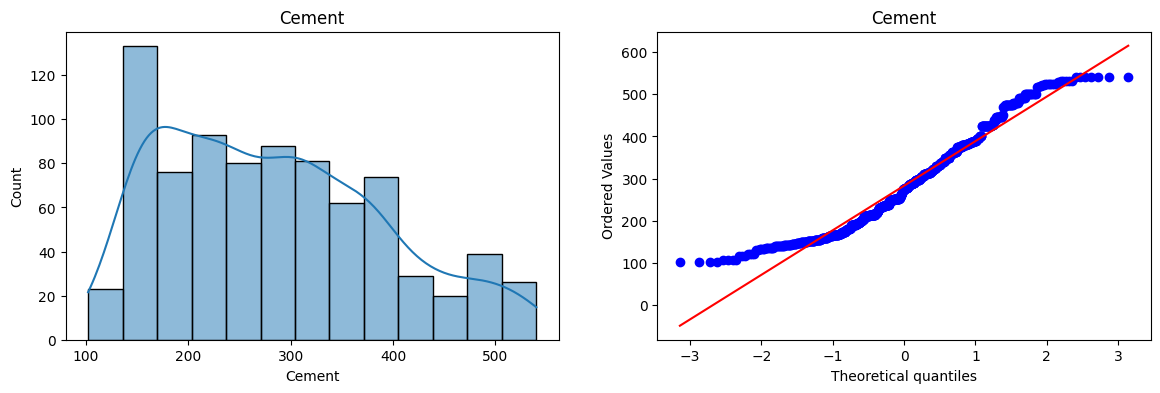

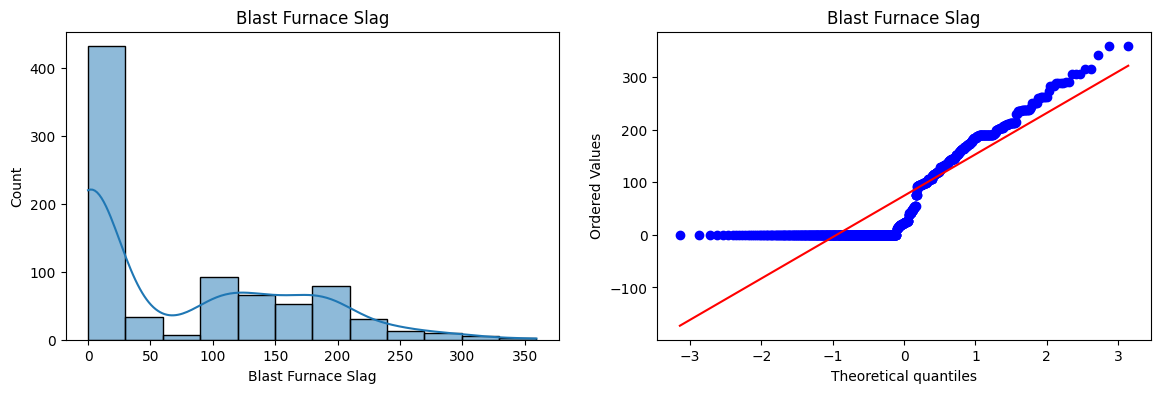

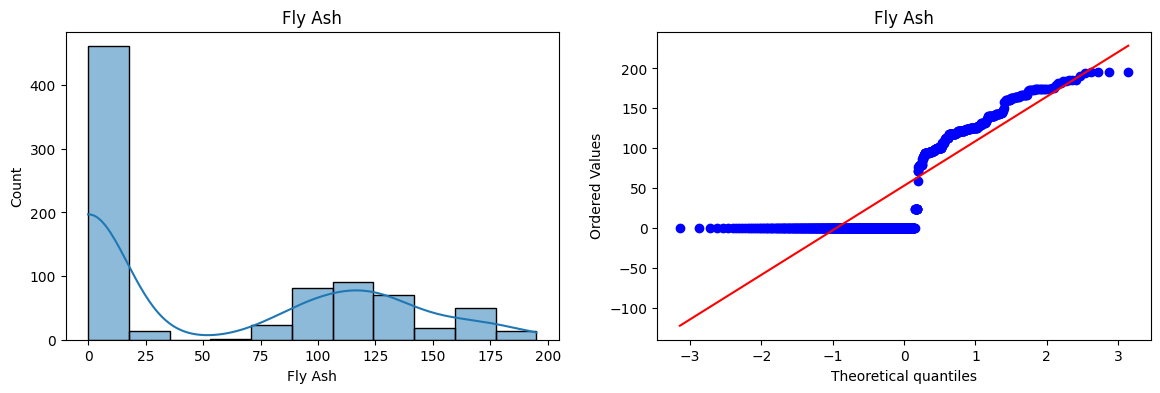

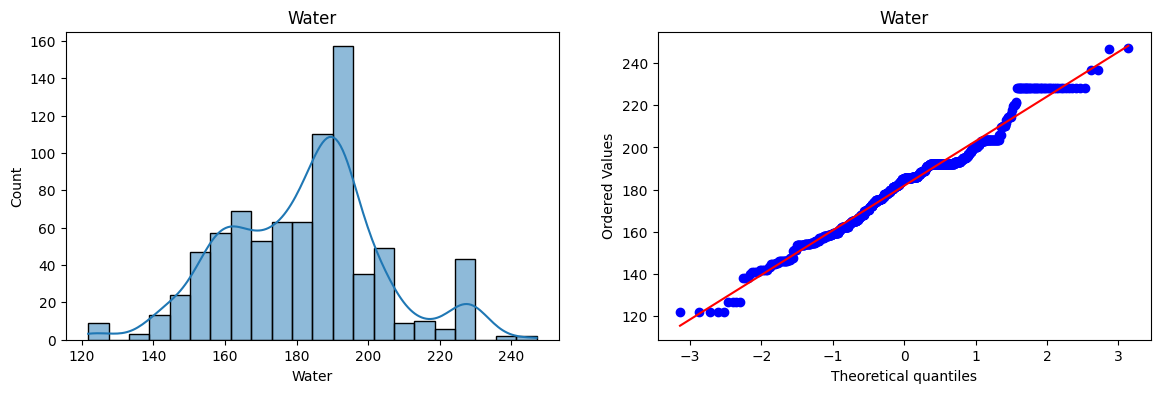

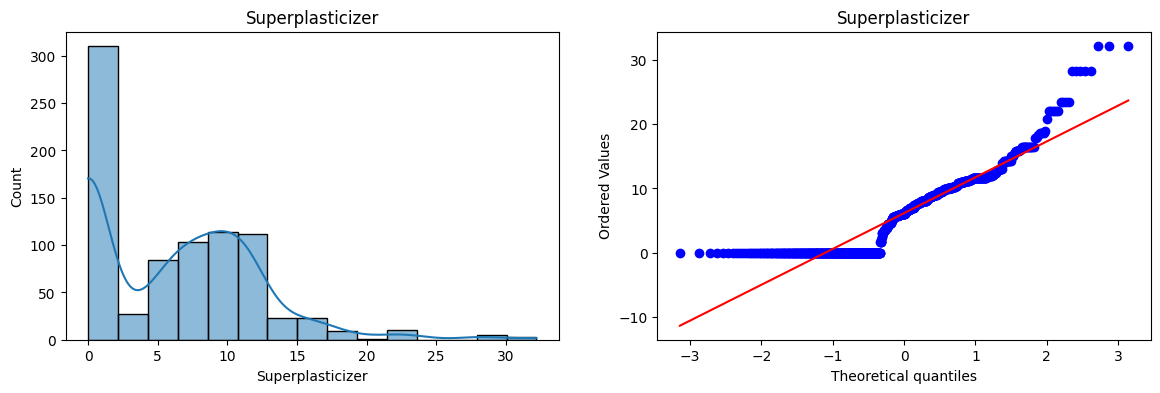

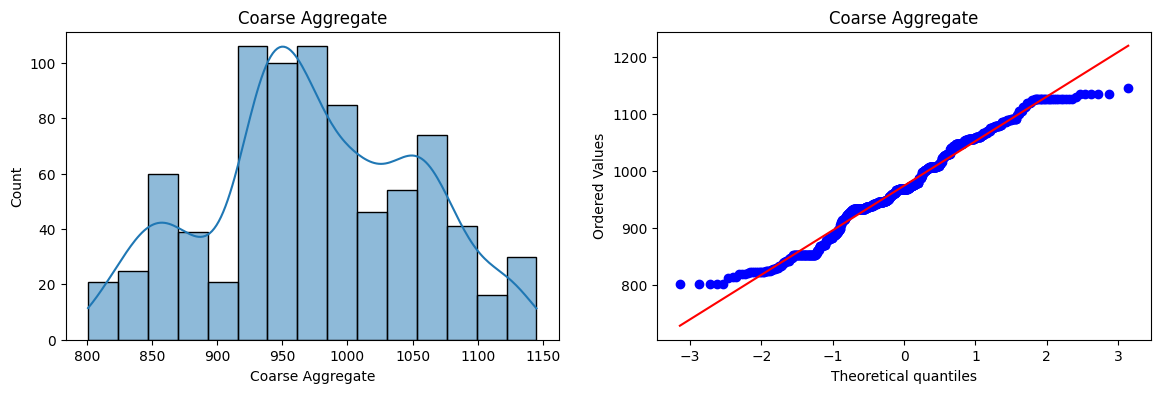

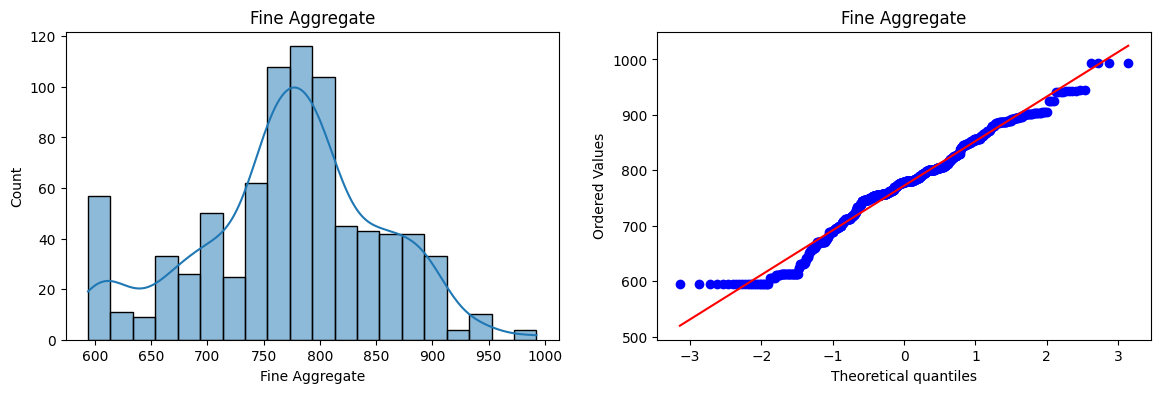

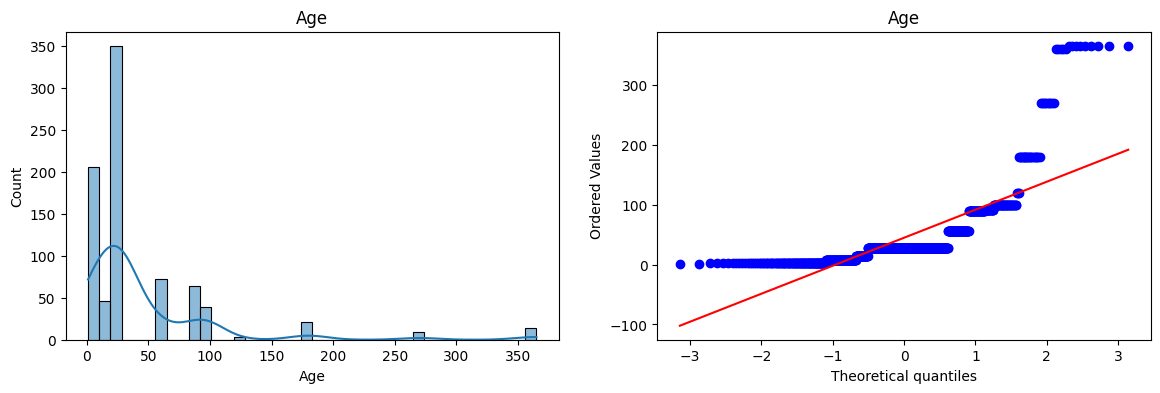

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

for col in x_train.columns:
    plt.figure(figsize=(14,4))

    # Histogram / Distribution plot
    plt.subplot(1, 2, 1)
    sns.histplot(x_train[col], kde=True)
    plt.title(col)

    # QQ Plot
    plt.subplot(1, 2, 2)
    stats.probplot(x_train[col], dist="norm", plot=plt)
    plt.title(col)

    plt.show()

In [37]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [38]:
x_train_scaled

array([[0.12922374, 0.41430161, 0.59487179, ..., 0.44273256, 0.31535374,
        0.07417582],
       [0.73515982, 0.06121313, 0.67692308, ..., 0.06104651, 0.39136979,
        0.07417582],
       [0.39520548, 0.        , 0.6225641 , ..., 0.73430233, 0.46036126,
        0.00549451],
       ...,
       [0.20159817, 0.        , 0.64205128, ..., 0.80813953, 0.51404917,
        0.27197802],
       [0.85159817, 0.33055092, 0.        , ..., 0.14854651, 0.47039639,
        0.07417582],
       [0.48401826, 0.        , 0.57948718, ..., 0.36046512, 0.47415956,
        0.07417582]], shape=(824, 8))

In [39]:
pt = PowerTransformer(method='box-cox')

x_train_transformed = pt.fit_transform(x_train+0.000001)
x_test_transformed = pt.fit_transform(x_train+0.0000001)

pd.DataFrame({'col' : x_train.columns, 'box_col_lambdas' : pt.lambdas_})

,col,box_col_lambdas
0,Cement,0.177025
1,Blast Furnace Slag,0.022767
2,Fly Ash,-0.034635
3,Water,0.772682
4,Superplasticizer,0.087141
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [40]:
# applying liner regression on transformation 

lr = LinearRegression()
lr.fit(x_train_transformed, y_train)

x_test_transformed = pt.transform(x_test + 0.000001)

y_pred2 = lr.predict(x_test_transformed)

r2_score(y_test, y_pred2)

0.8077075723002902

In [41]:
# using cross val score 

pt = PowerTransformer(method='box-cox')
x_traansformed = pt.fit_transform(x+0.000001)

lr = LinearRegression()
np.mean(cross_val_score(lr, x_traansformed, y, scoring='r2'))


np.float64(0.6662950326831086)

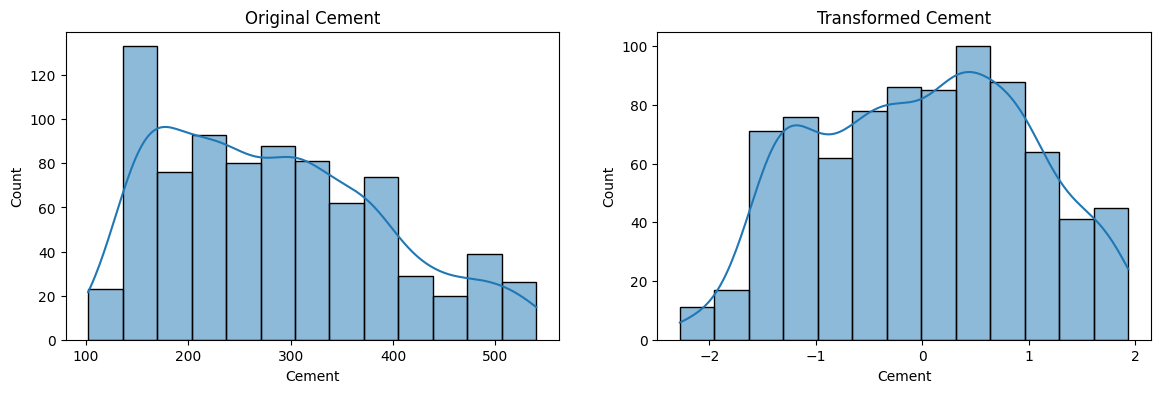

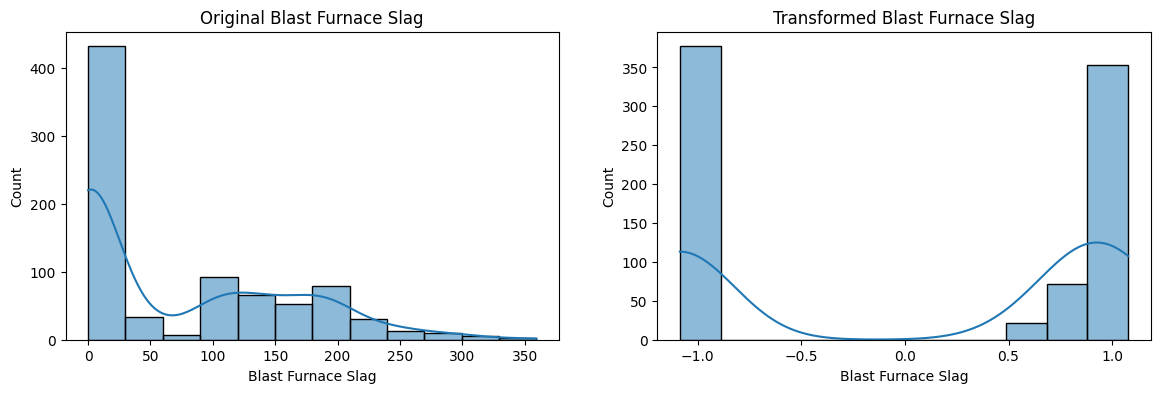

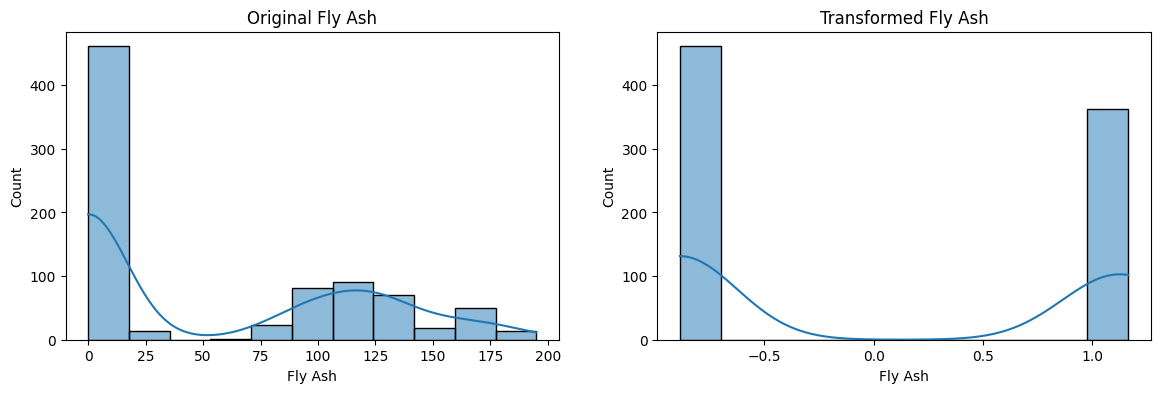

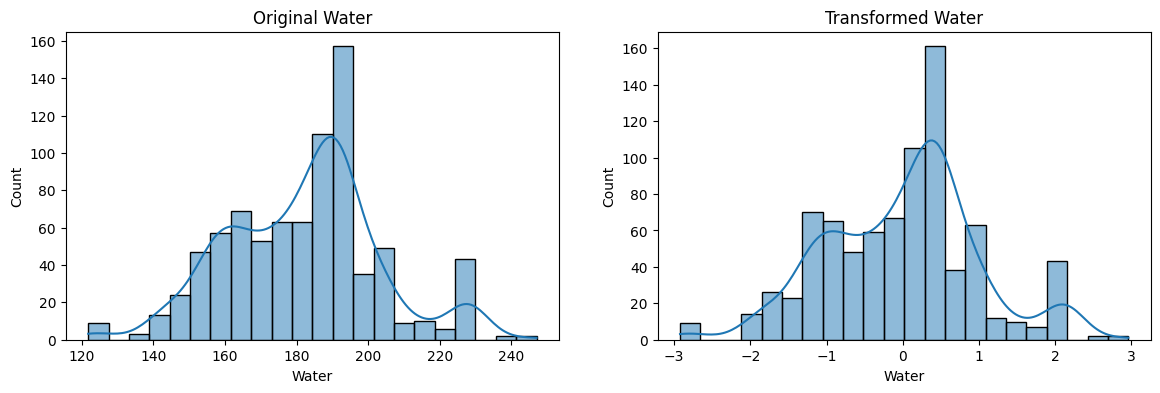

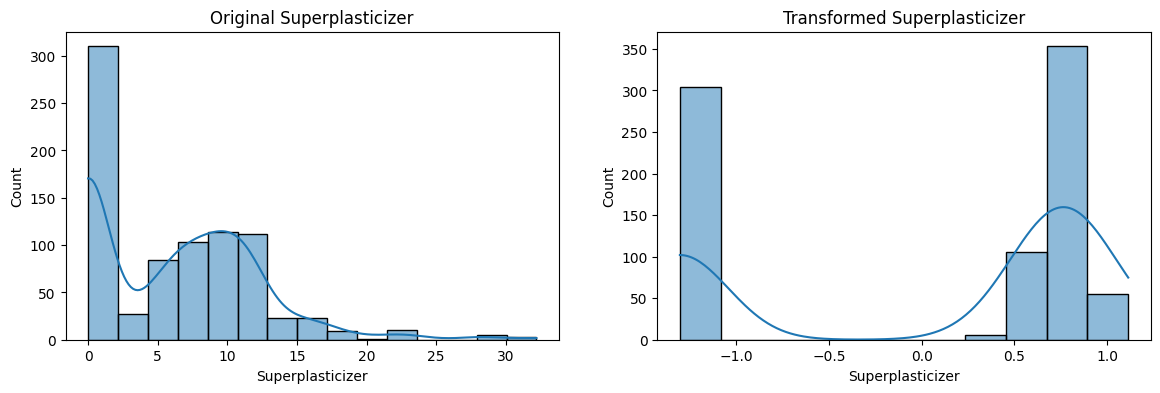

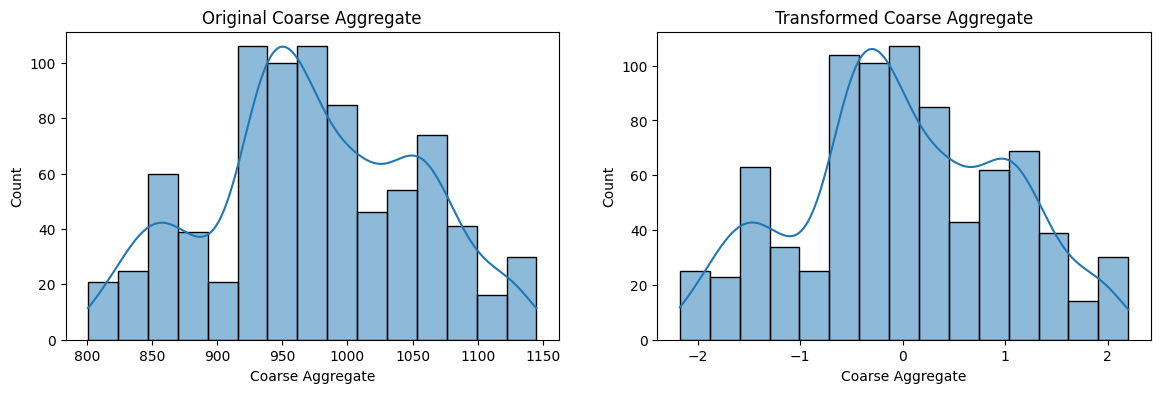

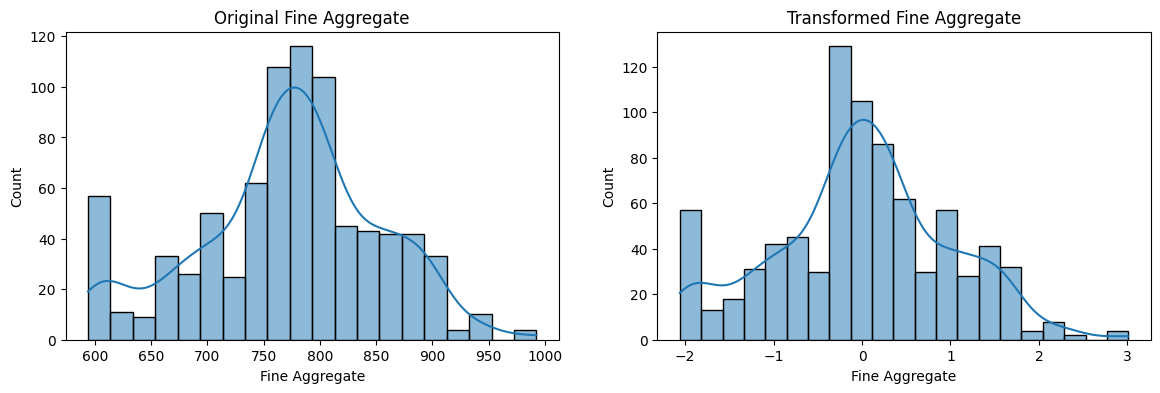

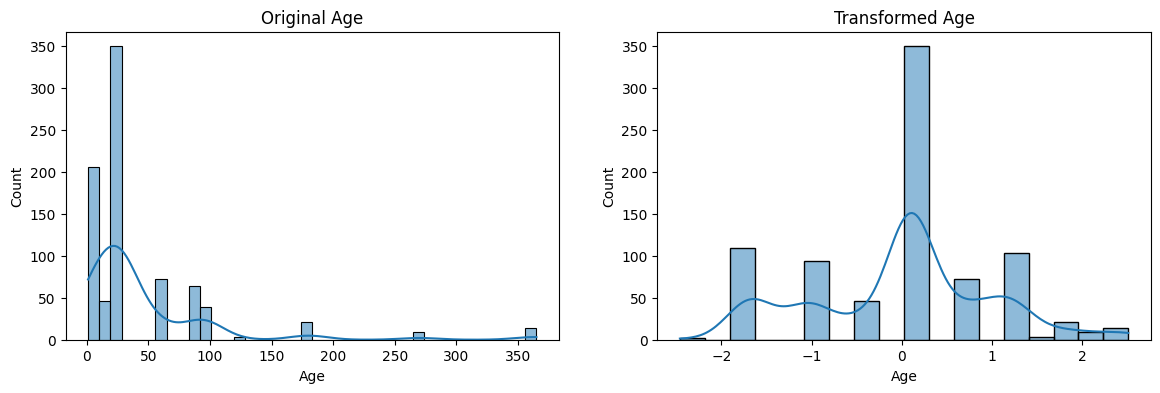

In [46]:
# before and after comparision for box-cox plot 

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

x_train_transformed = pd.DataFrame(x_train_transformed, columns=x_train.columns)

for col in x_train_transformed.columns:
    plt.figure(figsize=(14,4))

    # Original data
    plt.subplot(1,2,1)
    sns.histplot(x_train[col], kde=True)
    plt.title("Original " + col)

    # Transformed data
    plt.subplot(1,2,2)
    sns.histplot(x_train_transformed[col], kde=True)
    plt.title("Transformed " + col)

    plt.show()

# apply yeo-johnson transfromed 

In [48]:
pt1 = PowerTransformer()

x_train_transformed2 = pt1.fit_transform(x_train)
x_test_transformed2 = pt1.fit_transform(x_test)

lr = LinearRegression()
lr.fit(x_train_transformed2, y_train)

y_pred3 = lr.predict(x_test_transformed2)

print(r2_score(y_test, y_pred3))

pd.DataFrame({'col':x_train.columns, 'yeo_johnson_lambdas' : pt1.lambdas_})

0.8153845514645103


,col,yeo_johnson_lambdas
0,Cement,0.213025
1,Blast Furnace Slag,0.020476
2,Fly Ash,-0.038218
3,Water,0.958936
4,Superplasticizer,0.304951
5,Coarse Aggregate,1.192751
6,Fine Aggregate,1.975085
7,Age,-0.062443


In [49]:
pt = PowerTransformer()
x_traansformed2 = pt.fit_transform(x)

lr = LinearRegression()
np.mean(cross_val_score(lr,x_traansformed2, y, scoring='r2'))

np.float64(0.6834625126992433)

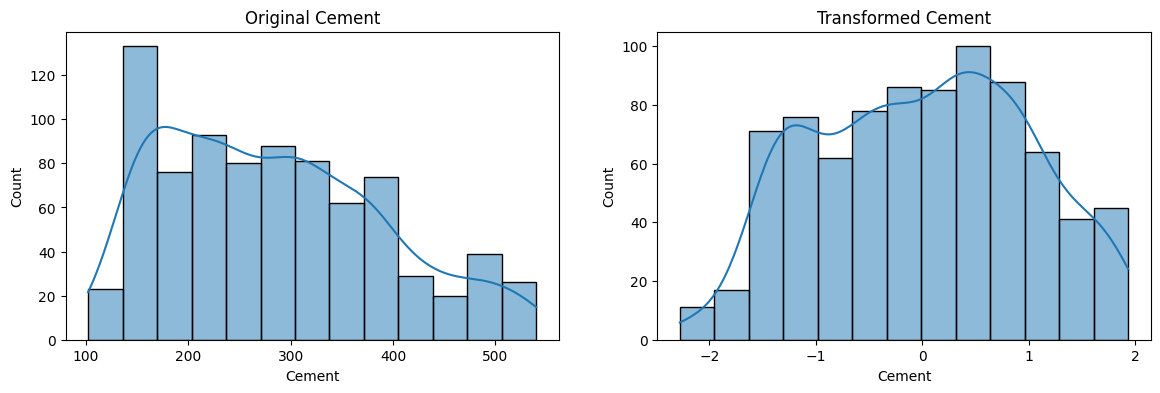

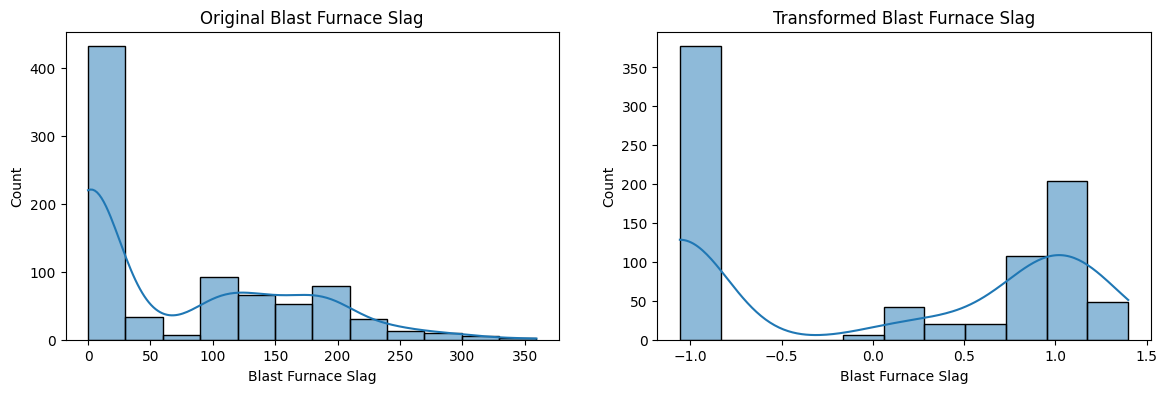

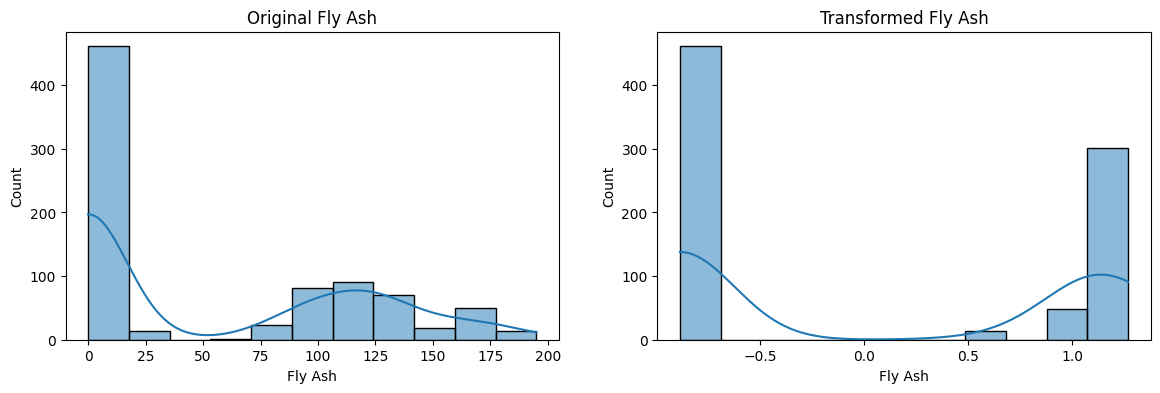

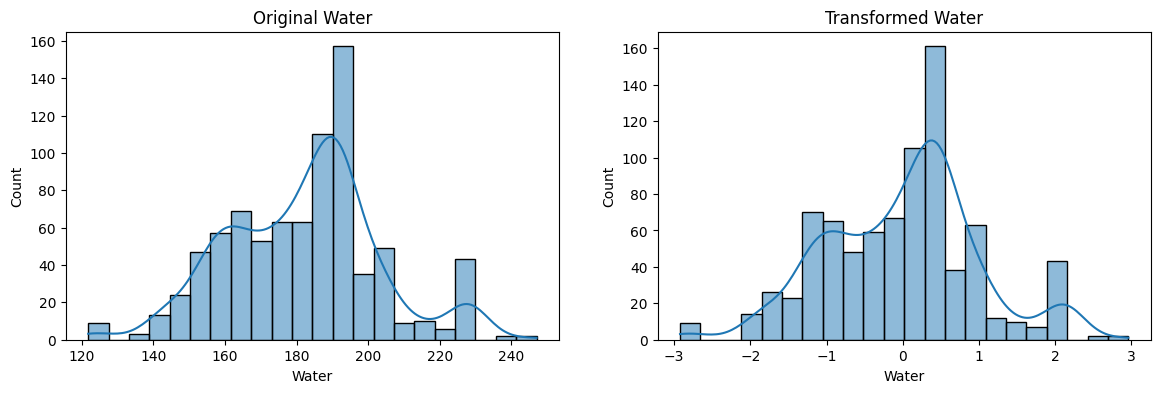

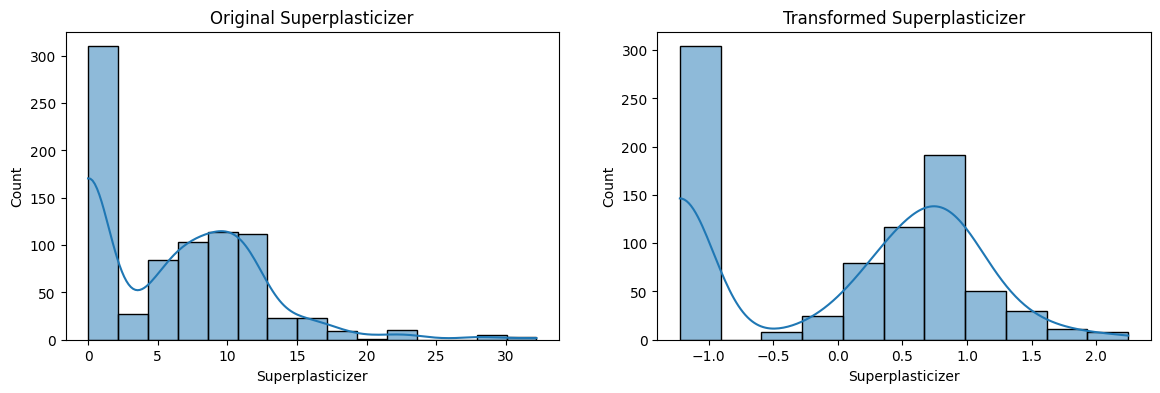

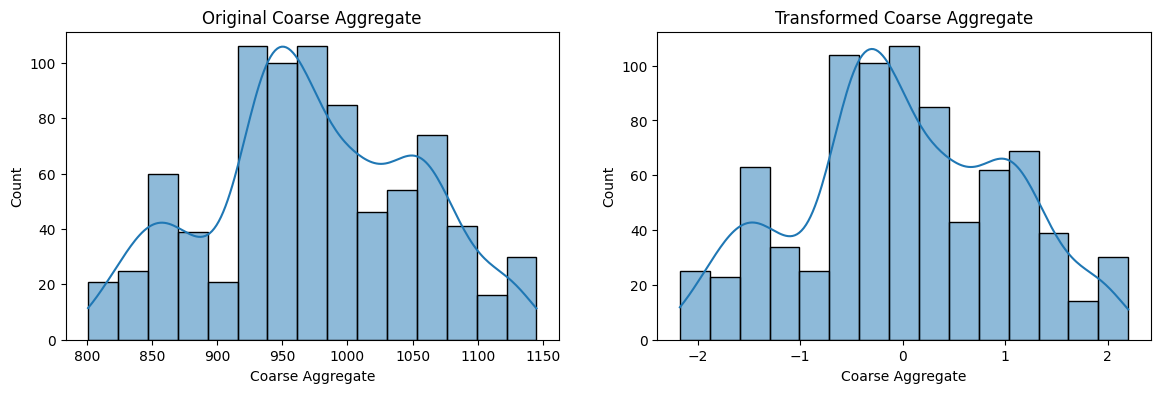

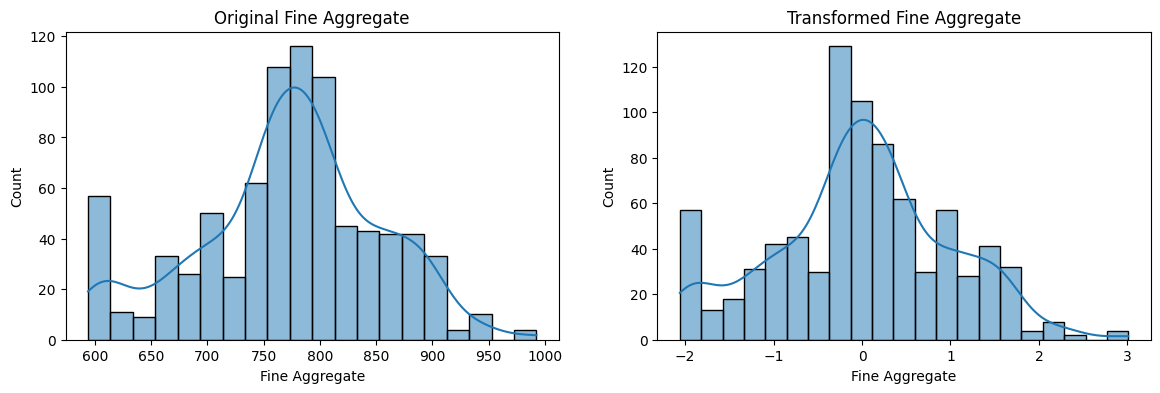

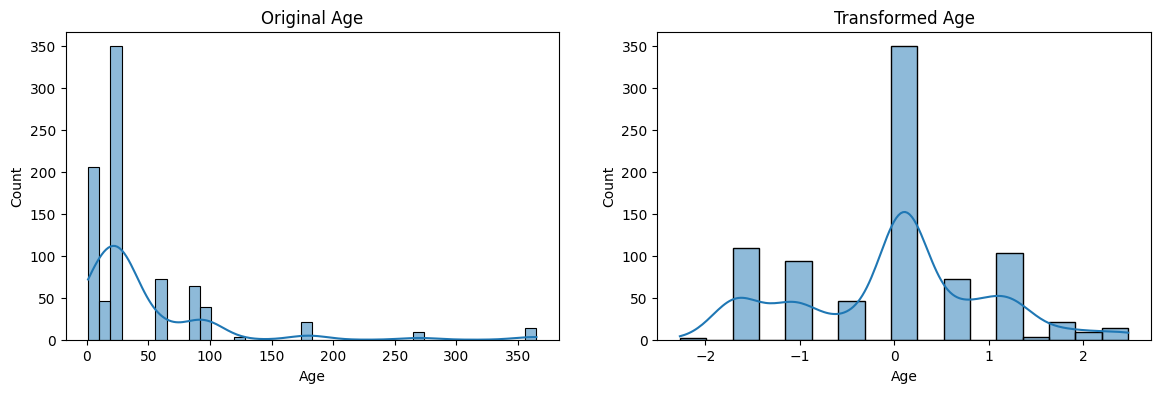

In [51]:
# x_train_transformed = pd.DataFrame(x_train_transformed, columns=x_train.columns)

x_train_transformed2 = pd.DataFrame(x_train_transformed2, columns=x_train.columns)

for col in x_train_transformed2.columns:
    plt.figure(figsize=(14,4))

    # Original data
    plt.subplot(1,2,1)
    sns.histplot(x_train[col], kde=True)
    plt.title("Original " + col)

    # Transformed data
    plt.subplot(1,2,2)
    sns.histplot(x_train_transformed2[col], kde=True)
    plt.title("Transformed " + col)

    plt.show()

In [52]:
# side by side lambda

pd.DataFrame({'col':x_train.columns, 'box_col_lambdas':pt.lambdas_, 'yeo_johnson_lambdas' : pt1.lambdas_})

,col,box_col_lambdas,yeo_johnson_lambdas
0,Cement,0.169544,0.213025
1,Blast Furnace Slag,0.016633,0.020476
2,Fly Ash,-0.136480,-0.038218
3,Water,0.808438,0.958936
4,Superplasticizer,0.264160,0.304951
5,Coarse Aggregate,1.129395,1.192751
6,Fine Aggregate,1.830764,1.975085
7,Age,0.001771,-0.062443
